Study the objectives for different attack objectives, L2 and cos distance.

In [1]:
import sys
import os

# Manually specify the path to your project folder
project_path = os.path.abspath('..')  # Or provide the full path if needed
sys.path.append(project_path)

# Now you can import from the sibling folder
from utilities import *
from helper import *

import torch.nn as nn
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms as T

import torchvision.datasets as datasets
from torch.utils.data import DataLoader
from models import *
import random
from collections import Counter
from collections import OrderedDict
import seaborn as sns
from copy import deepcopy
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


cos = nn.CosineSimilarity(dim=0, eps=1e-9) 
device = "cuda"

# study 1 model's training with the new loss function with dist limits

# adjustable parameters
# alpha_d = 100 # IID
iters = 30
learning_rate = 0.001

global attack 
attack = "untargeted" #"backdoor", "tlp", "ut"
model_name = "ConvNet" # "resnet8", "ConvNet"
num_classes = 10
dataset ="fmnist" # "cifar10", "fmnist"

/home2/liyang/micromamba/envs/fl39/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Total trainable parameters: 23332739


In [2]:
# Define transformation (convert images to tensors and normalize)
transform_img = T.Compose([
    T.ToTensor(),  # Convert image to tensor
    T.Normalize((0.5,), (0.5,))  # Normalize the image with mean and std
])

if dataset == "mnist":
    train_data = datasets.MNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.MNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "fmnist":
    train_data = datasets.FashionMNIST(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.FashionMNIST(root=f'{project_path}/data', train=False, download=True, transform=transform_img)
elif dataset == "cifar10":
    train_data = datasets.CIFAR10(root=f'{project_path}/data', train=True, download=True, transform=transform_img)
    test_data = datasets.CIFAR10(root=f'{project_path}/data', train=False, download=True, transform=transform_img)

In [3]:
# Create DataLoader for batch processing
fl_data_dict, labels_per_client_dict, label_count_per_client_dict =\
    create_data_fl_clients(client_num=100,
                           noniid_type="dirichlet",
                           label_skew_alpha =None,
                           p_degree=None,
                           dirichlet_alpha=100,
                           fl_train=train_data,
                           fl_class_num=10)
train_loader = DataLoader(fl_data_dict[0], batch_size=32, shuffle=True, num_workers=0)

In [4]:
label_count_per_client_dict[0]

{0: 52, 1: 58, 2: 58, 3: 58, 4: 63, 5: 53, 6: 68, 7: 67, 8: 56, 9: 80}

In [5]:
model_class = get_model(model_name)    
model_fn = partial(model_class, num_classes=num_classes, dataset=dataset)
# model0
model0 = model_fn().to(device)
model0_sd = deepcopy(model0.state_dict())
optimizer0 = optim.SGD(model0.parameters(), lr=learning_rate)
c_criterion0 = nn.CrossEntropyLoss()

# modelt 
modelt = model_fn().to(device)
modelt.load_state_dict(model0_sd)
optimizer1 = optim.SGD(modelt.parameters(), lr=learning_rate)
c_criterion1 = nn.CrossEntropyLoss()

In [6]:
# Helper: clone model parameters
def clone_model_params(model):
    return {name: param.detach().clone() for name, param in model.state_dict().items()}

# Helper: compute model update
def compute_model_update(current_state, previous_state):
    return {name: current_state[name] - previous_state[name] for name in current_state}

In [7]:
# Initialize
model_updates = {}  # store updates like {1: g_1, 2: g_2, ...}
prev_model_state = clone_model_params(model0)
accuracy_list =[]

# Normal training to converge
for iter in range(iters):
    train_c_model(train_loader, model0, c_criterion0, optimizer0, attack_method='none', client_id=0,
                  malicious_client_ids=[], optimizer_poison=None, dba_poisoning_per_batch=0.2, device=device)

    # Compute model update
    current_model_state = clone_model_params(model0)
    model_updates[iter + 1] = compute_model_update(current_model_state, prev_model_state)
    prev_model_state = current_model_state  # update for next iteration

    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(model0, c_criterion0, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
    accuracy_list.append(accuracy)
    print(f"iter:{iter}, accuracy:{accuracy}")

iter:0, accuracy:0.48
iter:1, accuracy:0.5245
iter:2, accuracy:0.6366
iter:3, accuracy:0.6448
iter:4, accuracy:0.657
iter:5, accuracy:0.671
iter:6, accuracy:0.6906
iter:7, accuracy:0.6746
iter:8, accuracy:0.7021
iter:9, accuracy:0.7027
iter:10, accuracy:0.7204
iter:11, accuracy:0.7107
iter:12, accuracy:0.7213
iter:13, accuracy:0.7275
iter:14, accuracy:0.7259
iter:15, accuracy:0.7274
iter:16, accuracy:0.7372
iter:17, accuracy:0.7299
iter:18, accuracy:0.7379
iter:19, accuracy:0.74
iter:20, accuracy:0.7417
iter:21, accuracy:0.7392
iter:22, accuracy:0.7373
iter:23, accuracy:0.7424
iter:24, accuracy:0.7484
iter:25, accuracy:0.756
iter:26, accuracy:0.7429
iter:27, accuracy:0.7483
iter:28, accuracy:0.7566
iter:29, accuracy:0.7541


In [8]:
# Flatten a model update (dict of tensors) into a single 1D tensor
def flatten_update(update_dict):
    return torch.cat([v.view(-1) for v in update_dict.values()])

# Step 1: Compute flattened updates
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]

# Step 1: L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Step 2: Cosine distance matrix (1 - cosine similarity)
cos_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))
for i in range(len(flattened_updates)):
    for j in range(len(flattened_updates)):
        cos_sim = F.cosine_similarity(flattened_updates[i], flattened_updates[j], dim=0).item()
        cos_diff_matrix[i, j] = 1 - cos_sim

# Step 3: L2 distance matrix
l2_diff_matrix = torch.zeros(len(flattened_updates), len(flattened_updates))
for i in range(len(flattened_updates)):
    for j in range(len(flattened_updates)):
        l2_diff = torch.norm(flattened_updates[i] - flattened_updates[j]).item()
        l2_diff_matrix[i, j] = l2_diff

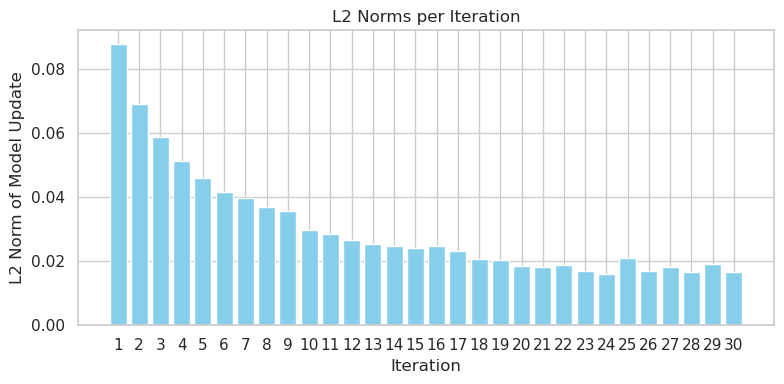

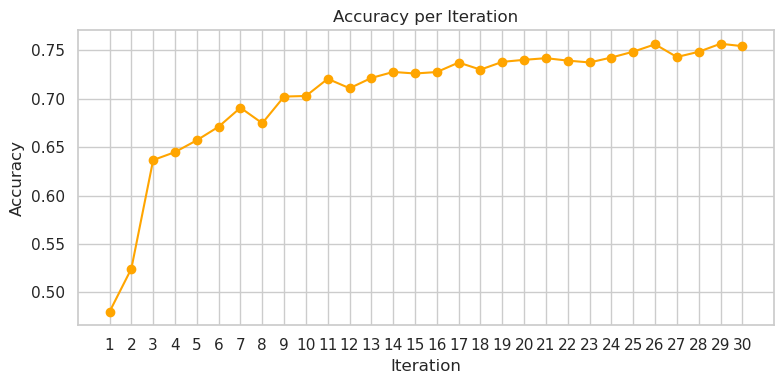

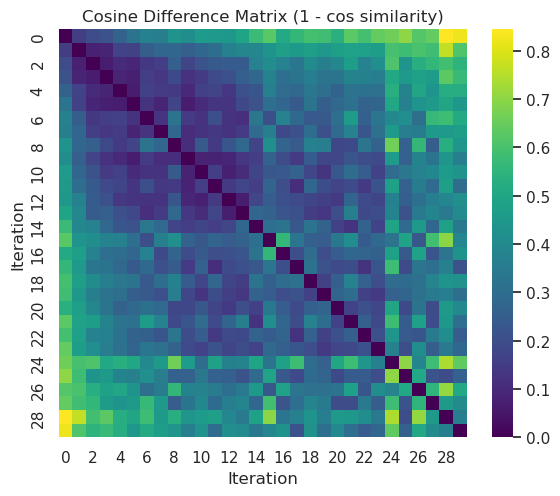

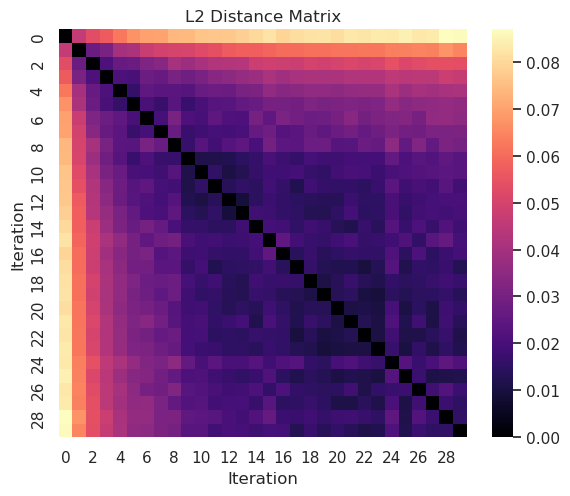

In [9]:

# Ensure seaborn styling
sns.set(style="whitegrid")

# Plot 1: Bar plot of L2 norms
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(l2_norms) + 1), l2_norms, color='skyblue')
plt.xlabel("Iteration")
plt.ylabel("L2 Norm of Model Update")
plt.title("L2 Norms per Iteration")
plt.xticks(range(1, len(l2_norms) + 1))
plt.tight_layout()
plt.show()

# Plot 2: Line plot of Accuracy per Iteration
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(accuracy_list) + 1), accuracy_list, color='orange', marker='o')
plt.xlabel("Iteration")
plt.ylabel("Accuracy")
plt.title("Accuracy per Iteration")
plt.xticks(range(1, len(accuracy_list) + 1))
plt.grid(True)  # Optional: adds grid lines for better readability
plt.tight_layout()
plt.show()


# Convert matrices to numpy
cos_diff_np = cos_diff_matrix.numpy()
l2_diff_np = l2_diff_matrix.numpy()

# Plot 3: Heatmap of cosine differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(cos_diff_np, annot=False, cmap="viridis", square=True)
plt.title("Cosine Difference Matrix (1 - cos similarity)")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()

# Plot 4: Heatmap of L2 differences (without annotations)
plt.figure(figsize=(6, 5))
sns.heatmap(l2_diff_np, annot=False, cmap="magma", square=True)
plt.title("L2 Distance Matrix")
plt.xlabel("Iteration")
plt.ylabel("Iteration")
plt.tight_layout()
plt.show()



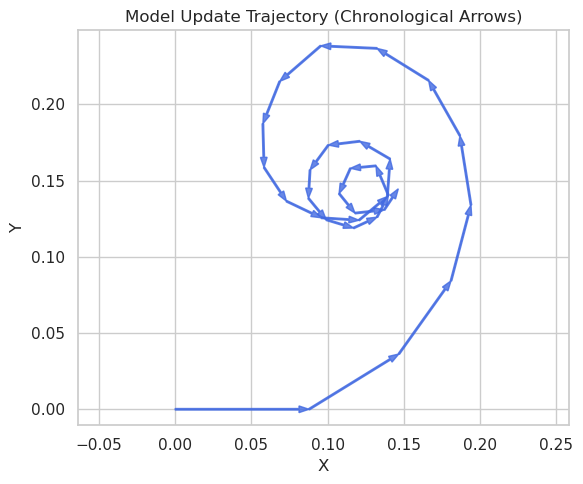

In [10]:
# plot the trajectory of model updates in 2D space

# Step 1: Flatten updates (if not already done)
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]

# Step 2: Get L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Step 3: Compute angles between successive updates
angles = [0.0]  # start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = F.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    # Determine rotation direction using sign of cross product
    sign = torch.sign(torch.dot(u_prev, u_curr))  # crude check
    if sign < 0:
        angle_diff = -angle_diff
    angles.append(angle_diff)

# Step 4: Convert to absolute angles
absolute_angles = [0.0]
for i in range(1, len(angles)):
    absolute_angles.append(absolute_angles[-1] + angles[i])

# Step 5: Compute vector endpoints
x, y = [0], [0]
for i in range(len(l2_norms)):
    dx = l2_norms[i] * np.cos(absolute_angles[i])
    dy = l2_norms[i] * np.sin(absolute_angles[i])
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)

# Step 6: Plot
plt.figure(figsize=(6, 5))
for i in range(len(l2_norms)):
    plt.arrow(x[i], y[i], x[i+1]-x[i], y[i+1]-y[i],
              head_width=0.05*max(l2_norms), length_includes_head=True,
              color='royalblue', alpha=0.8)

plt.title("Model Update Trajectory (Chronological Arrows)")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


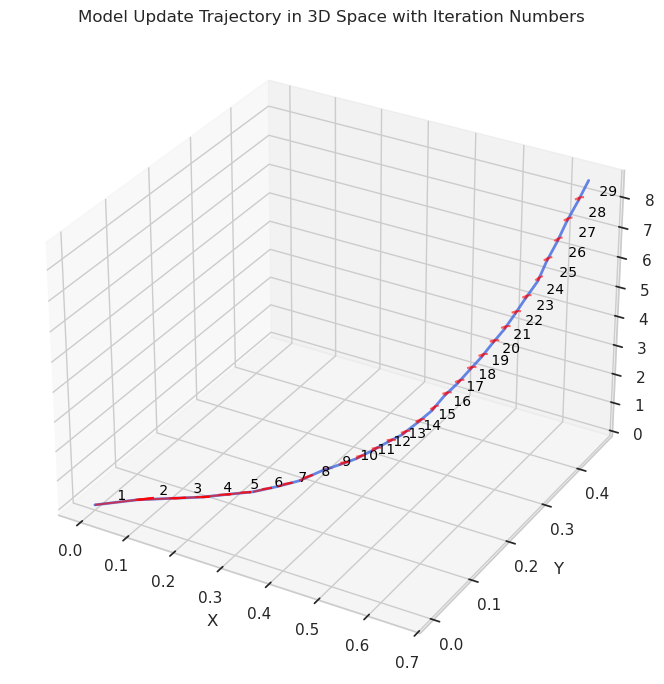

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from mpl_toolkits.mplot3d import Axes3D

# Assuming model_updates is a dictionary or list with flattened model updates
# You would replace the below code with your actual model update data.
flattened_updates = [flatten_update(model_updates[i]) for i in sorted(model_updates)]  # Flatten updates

# Calculate L2 norms
l2_norms = [u.norm().item() for u in flattened_updates]

# Compute angles between consecutive updates (using cosine similarity)
angles = [0.0]  # Start first arrow at 0 degrees (pointing right)
for i in range(1, len(flattened_updates)):
    u_prev = flattened_updates[i - 1]
    u_curr = flattened_updates[i]
    cos_sim = torch.cosine_similarity(u_prev, u_curr, dim=0).item()
    angle_diff = np.arccos(np.clip(cos_sim, -1.0, 1.0))  # radians
    angles.append(angle_diff)

# Compute 3D coordinates of the trajectory
x, y, z = [0], [0], [0]

# For simplicity, assume updates occur in 3D space
for i in range(1, len(l2_norms)):
    dx = l2_norms[i] * np.cos(angles[i])  # X direction
    dy = l2_norms[i] * np.sin(angles[i])  # Y direction
    dz = i * 0.02  # Slightly separate updates in the Z direction for clarity
    x.append(x[-1] + dx)
    y.append(y[-1] + dy)
    z.append(z[-1] + dz)

# Create 3D plot
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Plot the 3D trajectory path as a line
ax.plot(x, y, z, color='royalblue', alpha=0.8, linewidth=2)

# Plot arrows for each update
for i in range(len(l2_norms) - 1):
    ax.quiver(x[i], y[i], z[i], x[i+1] - x[i], y[i+1] - y[i], z[i+1] - z[i],
              length=0.1, normalize=True, color='red', alpha=0.6)

    # Add iteration number as a label near the arrows
    ax.text(x[i] + 0.02, y[i] + 0.02, z[i] + 0.02, f" {i+1}", color='black', fontsize=10)

# Labels and title
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title("Model Update Trajectory in 3D Space with Iteration Numbers")

# Display the plot
plt.tight_layout()
plt.show()


# Attack with budget on L2 norm


In [12]:
# copy the trained model0 to modelt
modelt.load_state_dict(model0.state_dict())

# test the modelt
test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(modelt, c_criterion1, 
                            test_data, server_batch_size=32, class_num=10, attack_method='none',
                            mali_labels=[0,7], device=device)
print(f"modelt accuracy:{accuracy}")

modelt accuracy:0.7541


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms


# Assuming `modelt` is your pre-trained model on Fashion-MNIST
# Assuming `train_loader` and `val_loader` are DataLoaders for your training and validation data

class NegativeCrossEntropyLoss(nn.Module):
    def __init__(self):
        super(NegativeCrossEntropyLoss, self).__init__()
        self.ce_loss = nn.CrossEntropyLoss()

    def forward(self, outputs, labels):
        return -self.ce_loss(outputs, labels)

def train_one_epoch_with_negative_ce(model, train_loader, device):
    model.train()
    neg_ce_loss = NegativeCrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.01)  # Adjust learning rate if needed

    # Save a copy of the original model parameters
    original_state = deepcopy(model.state_dict())

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = neg_ce_loss(outputs, labels)
        
        loss.backward()
        optimizer.step()
    
    # Calculate G_m as the difference between the new and original model parameters
    G_m = {name: model.state_dict()[name] - original_state[name] for name in model.state_dict()}
    model.load_state_dict(original_state)  # Restore original model parameters
    return G_m

def calculate_average_l2_norm(l2_norms):
    return sum(l2_norms) / len(l2_norms)

def calculate_l2_distance(original_weights, attacked_weights):
    """Calculate the L2 distance between two sets of weights."""
    return torch.norm(attacked_weights - original_weights).item()

def apply_attack(model, G_m, average_l2_norm, magnitudes):
    # Calculate the L2 norm of G_m
    total_norm = torch.sqrt(sum((G_m.norm() ** 2 for G_m in G_m.values())))
    
    # Normalize G_m by the average L2 norm
    normalized_G_m = {name: G_m * (average_l2_norm / total_norm) for name, G_m in G_m.items()}
    l2_distances = []
    attacked_models = []
    for magnitude in magnitudes:
        new_model = deepcopy(model)
        for name, param in new_model.named_parameters():
            param.data += magnitude * normalized_G_m[name]
        attacked_models.append(new_model)
        l2_distance = calculate_l2_distance(flatten_update(model.state_dict()), flatten_update(new_model.state_dict()))
        l2_distances.append(l2_distance)
    return attacked_models, l2_distances

def evaluate_model(model, val_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

def flatten_model(state_dict):
    """Flatten a model's state_dict into a single 1D tensor."""
    return torch.cat([param.flatten() for param in state_dict.values()])

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Assuming `l2_norms` is the list of L2 norms recorded during benign training
average_l2_norm = calculate_average_l2_norm(l2_norms)
print(f"Average L2 Norm: {average_l2_norm}")

# Calculate G_m
G_m = train_one_epoch_with_negative_ce(modelt, train_loader, device)
print("G_m norm", torch.norm(flatten_model(G_m)))

# Define magnitudes
L2_dists = [x * 0.25 for x in range(0, 9)] + list(range(2, 21))

# Apply attack and create malicious models
attacked_models, l2_distances = apply_attack(modelt, G_m, average_l2_norm, L2_dists)
attack_accuracy_list = []
# Evaluate each malicious model
for i, attackeG_model in enumerate(attacked_models):
    # accuracy = evaluate_model(attackeG_model, val_loader, device)
    test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(attackeG_model, c_criterion1, 
                        test_data, server_batch_size=32, class_num=10, attack_method='none',
                        mali_labels=[0,7], device=device)
    
    attack_accuracy_list.append(accuracy*100)
    print(f'Malicious Model {i} with magnitude {L2_dists[i]}: Accuracy = {accuracy * 100:.2f}%')


Average L2 Norm: 0.03043273128569126
G_m norm tensor(4.3867, device='cuda:0')
Malicious Model 0 with magnitude 0.0: Accuracy = 75.41%
Malicious Model 1 with magnitude 0.25: Accuracy = 75.51%
Malicious Model 2 with magnitude 0.5: Accuracy = 75.51%
Malicious Model 3 with magnitude 0.75: Accuracy = 75.37%
Malicious Model 4 with magnitude 1.0: Accuracy = 75.20%
Malicious Model 5 with magnitude 1.25: Accuracy = 74.84%
Malicious Model 6 with magnitude 1.5: Accuracy = 74.46%
Malicious Model 7 with magnitude 1.75: Accuracy = 73.80%
Malicious Model 8 with magnitude 2.0: Accuracy = 72.98%
Malicious Model 9 with magnitude 2: Accuracy = 72.98%
Malicious Model 10 with magnitude 3: Accuracy = 67.51%
Malicious Model 11 with magnitude 4: Accuracy = 63.14%
Malicious Model 12 with magnitude 5: Accuracy = 59.28%
Malicious Model 13 with magnitude 6: Accuracy = 54.51%
Malicious Model 14 with magnitude 7: Accuracy = 49.26%
Malicious Model 15 with magnitude 8: Accuracy = 42.69%
Malicious Model 16 with magnit

In [25]:
l2_distances[19]

0.3651927709579468

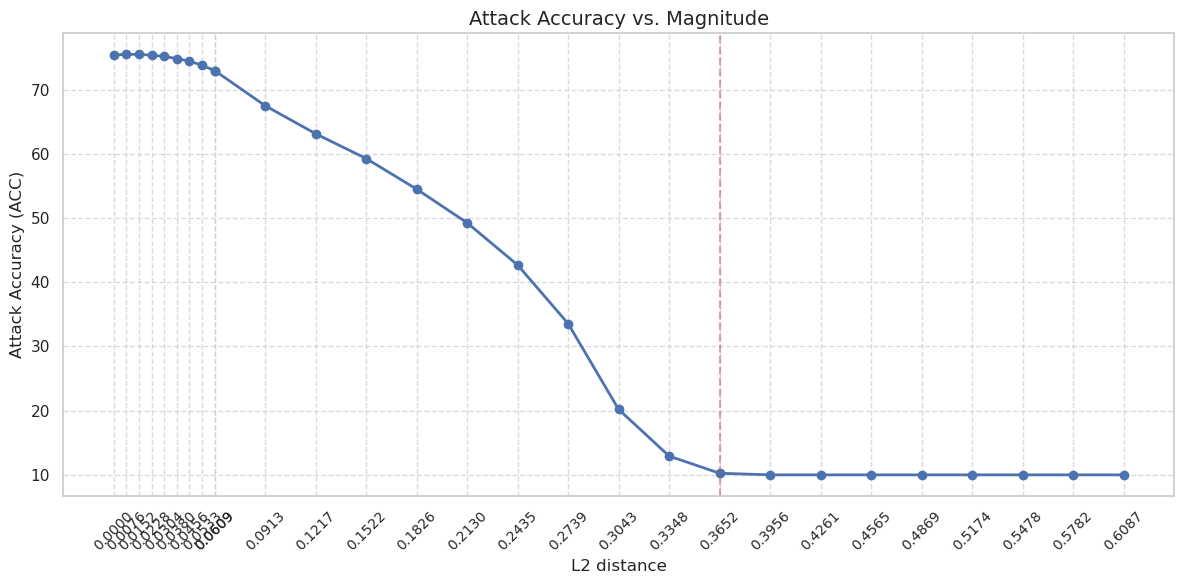

In [26]:
# Create the plot
plt.figure(figsize=(12, 6))
plt.plot(l2_distances, attack_accuracy_list, marker='o', linestyle='-', color='b', linewidth=2)

# Customize the plot
plt.title('Attack Accuracy vs. Magnitude', fontsize=14)
plt.xlabel('L2 distance', fontsize=12)
plt.ylabel('Attack Accuracy (ACC)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Set x-axis ticks: 
# - Show all 0.1 steps from 0.0 to 1.0
# - Then show 1.0 steps from 1.0 to max magnitude
# max_magnitude = max(magnitudes)
# xticks = magnitudes
max_l2 = max(l2_distances)
xticks = l2_distances
plt.xticks(xticks, fontsize=10)

# Rotate x-axis labels for better readability if many ticks
plt.xticks(rotation=45)

# Add a vertical line at magnitude=1 to mark the transition
plt.axvline(x=0.36519, color='r', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [27]:

# Flatten the models
original_flat = flatten_model(model0_sd)
benign_flat = flatten_model(modelt.state_dict())
attacked_flat = flatten_model(attacked_models[19].state_dict())

models = [original_flat, benign_flat, attacked_flat]
model_names = ["Original", "Benign", "Attacked"]

In [28]:
l2_diff_matrix = torch.zeros(3, 3)
for i in range(3):
    for j in range(3):
        l2_diff_matrix[i, j] = torch.norm(models[i] - models[j]).item()

print("\nL2 Distance Matrix:")
print(l2_diff_matrix)


L2 Distance Matrix:
tensor([[0.0000, 0.7646, 0.8675],
        [0.7646, 0.0000, 0.3652],
        [0.8675, 0.3652, 0.0000]])


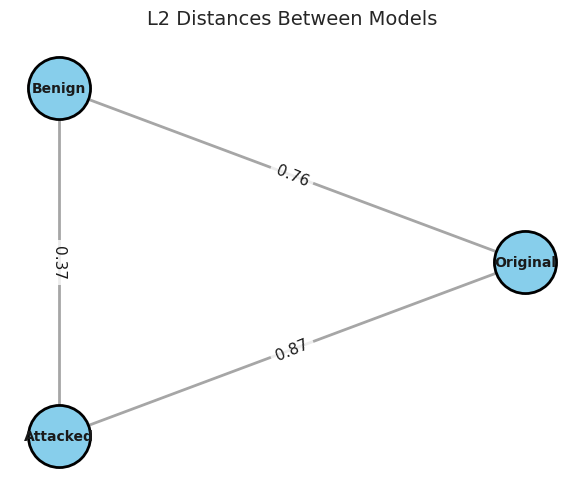

In [29]:
import networkx as nx

# Your data
l2_matrix = l2_diff_matrix

# Create graph
G = nx.Graph()

# Add nodes
for name in model_names:
    G.add_node(name)

# Add edges with rounded weights (2 decimal places)
for i in range(len(model_names)):
    for j in range(i+1, len(model_names)):
        rounded_weight = round(l2_matrix[i, j].item(), 2)  # Round to 2 decimals
        G.add_edge(model_names[i], model_names[j], weight=rounded_weight)

# Position nodes in a triangle
pos = nx.circular_layout(G)

# Draw nodes and labels
plt.figure(figsize=(6, 5))
nx.draw_networkx_nodes(G, pos, node_size=2000, node_color='skyblue', edgecolors='black', linewidths=2)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight='bold')

# Draw edges with clean labels
nx.draw_networkx_edges(G, pos, width=2, edge_color='gray', alpha=0.7)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos, 
    edge_labels=edge_labels, 
    font_size=11,
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8)  # Clean background
)

# Title and aesthetics
plt.title("L2 Distances Between Models", pad=20, fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# for each layer we test the sensitivity in regards of the attack

def apply_attack_to_specific_layer(model, G_m, l2_budget, layer_name):
    # Calculate the total L2 norm of the gradient update for normalization
    total_norm = torch.sqrt(sum((g_m.norm() ** 2 for g_m in G_m.values())))
    normalized_G_m = {name: g_m * (l2_budget / total_norm) for name, g_m in G_m.items()}

    new_model = deepcopy(model)
    for name, param in new_model.named_parameters():
        if name == layer_name:
            # Calculate the current L2 norm of the specific layer's update
            current_layer_norm = normalized_G_m[name].norm()
            
            # Calculate the magnitude needed to achieve the specified L2 budget
            if current_layer_norm != 0:
                magnitude = l2_budget / current_layer_norm
            else:
                magnitude = 0  # Avoid division by zero
            
            # Apply the calculated magnitude to achieve the L2 budget
            param.data += magnitude * normalized_G_m[name]

    return new_model


def evaluate_and_record_sensitivities(model, G_m, max_l2, num_records, test_data, device):
    layer_names = [name for name, _ in model.named_parameters()]
    # Create a sequence of L2 distances
    l2_dists = np.linspace(0, max_l2, num_records)
    results_matrix = np.zeros((len(layer_names), len(l2_dists)))
    print("layer_names", layer_names)
    
    for layer_index, layer_name in enumerate(layer_names):
        print(f"Evaluating layer: {layer_name}")
        for idx, l2_budget in enumerate(l2_dists):
            attacked_model = apply_attack_to_specific_layer(model, G_m, l2_budget, layer_name)
            test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(
                attacked_model, c_criterion1, test_data, server_batch_size=32, class_num=10,
                attack_method='none', mali_labels=[0, 7], device=device
            )
            results_matrix[layer_index, idx] = accuracy
            print(f"Layer: {layer_name}, L2 Budget: {l2_budget}, Accuracy: {accuracy}")

    return results_matrix, layer_names, l2_dists



def plot_sensitivity_matrix(results_matrix, layer_names, L2_dists):
    plt.figure(figsize=(12, 8))
    plt.imshow(results_matrix, aspect='auto', cmap='viridis', origin='lower')
    plt.colorbar(label='Accuracy')
    plt.xlabel('L2 Distance')
    plt.ylabel('Layer Index')
    plt.xticks(ticks=np.arange(len(L2_dists)), labels=L2_dists)
    plt.yticks(ticks=np.arange(len(layer_names)), labels=layer_names)
    plt.title('Sensitivity Analysis of Layers to Attack')
    plt.show()

layer_names ['features.0.weight', 'features.0.bias', 'features.1.weight', 'features.1.bias', 'features.4.weight', 'features.4.bias', 'features.5.weight', 'features.5.bias', 'features.8.weight', 'features.8.bias', 'features.9.weight', 'features.9.bias', 'classifier.weight', 'classifier.bias']
Evaluating layer: features.0.weight


Layer: features.0.weight, L2 Budget: 0.0, Accuracy: 0.7541
Layer: features.0.weight, L2 Budget: 0.019221052631578948, Accuracy: 0.7545
Layer: features.0.weight, L2 Budget: 0.038442105263157896, Accuracy: 0.7547
Layer: features.0.weight, L2 Budget: 0.05766315789473685, Accuracy: 0.7551
Layer: features.0.weight, L2 Budget: 0.07688421052631579, Accuracy: 0.7547
Layer: features.0.weight, L2 Budget: 0.09610526315789474, Accuracy: 0.7548
Layer: features.0.weight, L2 Budget: 0.1153263157894737, Accuracy: 0.7548
Layer: features.0.weight, L2 Budget: 0.13454736842105264, Accuracy: 0.7548
Layer: features.0.weight, L2 Budget: 0.15376842105263158, Accuracy: 0.7548
Layer: features.0.weight, L2 Budget: 0.17298947368421053, Accuracy: 0.7546
Layer: features.0.weight, L2 Budget: 0.19221052631578947, Accuracy: 0.7539
Layer: features.0.weight, L2 Budget: 0.21143157894736841, Accuracy: 0.7542
Layer: features.0.weight, L2 Budget: 0.2306526315789474, Accuracy: 0.7547
Layer: features.0.weight, L2 Budget: 0.24

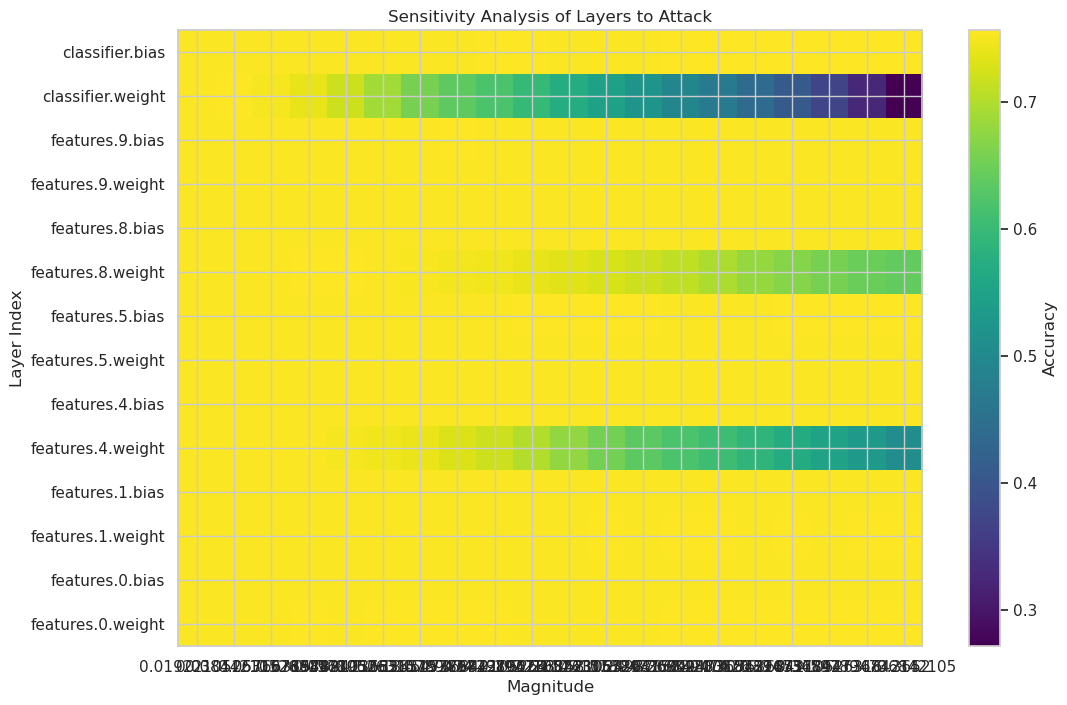

In [ ]:
# Evaluate and record sensitivities
results_matrix, layer_names, L2_dists = evaluate_and_record_sensitivities(
    modelt, G_m, 0.3652, 20, test_data, device
)

In [33]:
# Plot the sensitivity matrix
plot_sensitivity_matrix(results_matrix, layer_names, L2_dists)

NameError: name 'L2_dists' is not defined

Magnitude: 1, L2 Distance: 0.027369562536478043, Accuracy: 0.767
Magnitude: 2, L2 Distance: 0.054739125072956085, Accuracy: 0.7551
Magnitude: 3, L2 Distance: 0.08210869133472443, Accuracy: 0.7237
Magnitude: 4, L2 Distance: 0.10947824269533157, Accuracy: 0.6774
Magnitude: 5, L2 Distance: 0.13684780895709991, Accuracy: 0.617
Magnitude: 6, L2 Distance: 0.16421736776828766, Accuracy: 0.5589
Magnitude: 7, L2 Distance: 0.1915869414806366, Accuracy: 0.5064
Magnitude: 8, L2 Distance: 0.21895648539066315, Accuracy: 0.4696
Magnitude: 9, L2 Distance: 0.24632605910301208, Accuracy: 0.4323
Magnitude: 10, L2 Distance: 0.27369561791419983, Accuracy: 0.3825
Magnitude: 11, L2 Distance: 0.3010651767253876, Accuracy: 0.3291
Magnitude: 12, L2 Distance: 0.3284347355365753, Accuracy: 0.2774
Magnitude: 13, L2 Distance: 0.35580432415008545, Accuracy: 0.2069
Magnitude: 14, L2 Distance: 0.3831738829612732, Accuracy: 0.1319
Magnitude: 15, L2 Distance: 0.41054341197013855, Accuracy: 0.1015
Magnitude: 16, L2 Dista

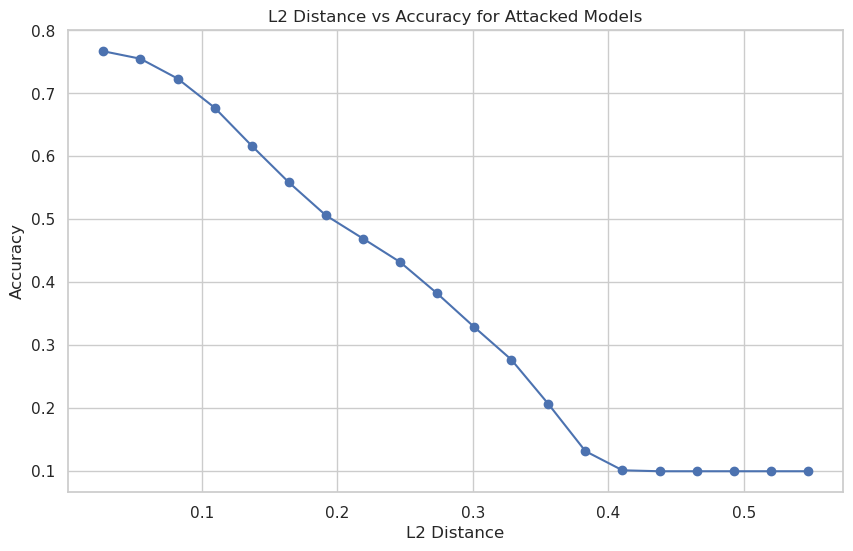

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from copy import deepcopy

# Assuming fl_validation and other necessary components are available



def evaluate_l2_distances_and_accuracies(model, G_m, average_l2_norm, test_data, device):
    layer_name = 'classifier.weight'
    magnitudes = list(range(1, 21))  # Magnitudes from 1 to 20
    l2_distances = []
    accuracies = []

    # Save the original weights for comparison
    original_weights = deepcopy(dict(model.named_parameters())[layer_name].data)

    for magnitude in magnitudes:
        attacked_model = apply_attack_to_specific_layer(model, G_m, average_l2_norm, magnitude, layer_name)
        attacked_weights = dict(attacked_model.named_parameters())[layer_name].data
        l2_distance = calculate_l2_distance(original_weights, attacked_weights)

        # Evaluate the attacked model
        test_loss, accuracy, per_class_accuracy, attack_success_rate = fl_validation(
            attacked_model, c_criterion1, test_data, server_batch_size=32, class_num=10,
            attack_method='none', mali_labels=[0, 7], device=device
        )

        l2_distances.append(l2_distance)
        accuracies.append(accuracy)

        print(f"Magnitude: {magnitude}, L2 Distance: {l2_distance}, Accuracy: {accuracy}")

    return l2_distances, accuracies

def plot_l2_distances_vs_accuracies(l2_distances, accuracies):
    plt.figure(figsize=(10, 6))
    plt.plot(l2_distances, accuracies, marker='o')
    plt.xlabel('L2 Distance')
    plt.ylabel('Accuracy')
    plt.title('L2 Distance vs Accuracy for Attacked Models')
    plt.grid(True)
    plt.show()

# Assuming `modelt` is your pre-trained model and `l2_norms` is available
average_l2_norm = calculate_average_l2_norm(l2_norms)
G_m = train_one_epoch_with_negative_ce(modelt, train_loader, device)

# Evaluate L2 distances and accuracies
l2_distances, accuracies = evaluate_l2_distances_and_accuracies(
    modelt, G_m, average_l2_norm, test_data, device
)

# Plot the results
plot_l2_distances_vs_accuracies(l2_distances, accuracies)


In [22]:
import torch
from copy import deepcopy

def train_one_epoch_with_negative_ce(model, train_loader, device):
    model.train()
    neg_ce_loss = NegativeCrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.01)  # Adjust learning rate if needed

    # Save a copy of the original model parameters
    original_state = deepcopy(model.state_dict())

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = neg_ce_loss(outputs, labels)
        
        loss.backward()
        optimizer.step()
    
    # Calculate G_m as the difference between the new and original model parameters
    G_m = {name: model.state_dict()[name] - original_state[name] for name in model.state_dict()}
    model.load_state_dict(original_state)  # Restore original model parameters
    return G_m

def compute_layer_l2_norms(G_m):
    layer_norms = {}
    total_norm = 0

    # Compute L2 norm for each layer
    for name, param_diff in G_m.items():
        layer_norm = torch.norm(param_diff).item()
        layer_norms[name] = layer_norm
        total_norm += layer_norm

    return layer_norms, total_norm

def compute_layer_norm_percentages(layer_norms, total_norm):
    layer_percentages = {name: (norm / total_norm) * 100 for name, norm in layer_norms.items()}
    return layer_percentages


# Compute L2 norms and percentages
layer_norms, total_norm = compute_layer_l2_norms(G_m)
layer_percentages = compute_layer_norm_percentages(layer_norms, total_norm)

# Display the results
print("Layer L2 Norms:")
for name, norm in layer_norms.items():
    print(f"{name}: {norm:.4f}")
print("total_norm", total_norm)
print("\nLayer Norm Percentages:")
for name, percentage in layer_percentages.items():
    print(f"{name}: {percentage:.2f}%")


Layer L2 Norms:
features.0.weight: 0.0999
features.0.bias: 0.0000
features.1.weight: 0.0173
features.1.bias: 0.0149
features.4.weight: 0.7798
features.4.bias: 0.0000
features.5.weight: 0.0268
features.5.bias: 0.0267
features.8.weight: 1.0745
features.8.bias: 0.0000
features.9.weight: 0.4683
features.9.bias: 0.3912
classifier.weight: 3.2898
classifier.bias: 0.1236
total_norm 6.312693670547903

Layer Norm Percentages:
features.0.weight: 1.58%
features.0.bias: 0.00%
features.1.weight: 0.27%
features.1.bias: 0.24%
features.4.weight: 12.35%
features.4.bias: 0.00%
features.5.weight: 0.42%
features.5.bias: 0.42%
features.8.weight: 17.02%
features.8.bias: 0.00%
features.9.weight: 7.42%
features.9.bias: 6.20%
classifier.weight: 52.11%
classifier.bias: 1.96%


In [23]:
def flatten_and_compute_total_norm(G_m):
    # Flatten all parameter updates into a single vector
    flat_vector = torch.cat([param_diff.flatten() for param_diff in G_m.values()])
    
    # Compute the total L2 norm of the flattened vector
    total_norm = torch.norm(flat_vector).item()
    
    return total_norm

flatten_and_compute_total_norm(G_m)

3.6034722328186035